# Produce figures of ISG clusters

In [ ]:
from pygenomeviz import GenomeViz

Found 5 protein-coding genes  |  region 187,195,486 – 187,717,691 bp


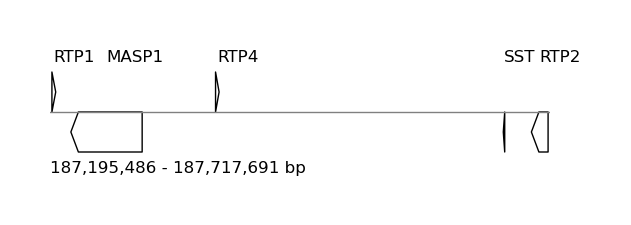

In [ ]:
# GFF files downloaded for human ISGs of interest from Ensembl on 2026-06-01
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_mx1_mx2.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_oas1_oas2_oas3.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_btn.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_trim5.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_plscr.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_ifitm.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_ifit.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_ifitm_ch_11_280k-380k.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_trim5_ch_11_5.58mb-5.76mb.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_btn_ch_6_26.26mb-26.30mb.gff"
#GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_btn_ch_6_26.26mb-26.56mb.gff"
GFF_FILE = "../additional_files/human_isg_clusters/gff/cluster_rtp_ch_3_187.20mb-187.72mb.gff"

genes = {}   # gene_id -> {start, end, strand, name}

with open(GFF_FILE) as fh:
    for line in fh:
        if line.startswith("#"):
            continue
        cols = line.strip().split("\t")
        if len(cols) < 9:
            continue

        attrs = dict(kv.split("=", 1) for kv in cols[8].split(";") if "=" in kv)

        if attrs.get("gene_type") != "protein_coding":
            continue

        gene_id = attrs.get("gene_id", "")
        start   = int(cols[3])
        end     = int(cols[4])
        strand  = 1 if cols[6] == "+" else -1

        raw  = gene_id
        name = raw[5:].split(".")[0] if raw.startswith("gene-") else raw.split(".")[0]

        # Skip Ensembl/Ensembl-EST gene IDs
        if name.startswith("ENSG") or name.startswith("ENSESTG"):
            continue

        if gene_id not in genes:
            genes[gene_id] = {"start": start, "end": end, "strand": strand, "name": name}
        else:
            genes[gene_id]["start"] = min(genes[gene_id]["start"], start)
            genes[gene_id]["end"]   = max(genes[gene_id]["end"],   end)

gene_list    = sorted(genes.values(), key=lambda x: x["start"])
region_start = gene_list[0]["start"]  - 2000
region_end   = gene_list[-1]["end"]   + 2000

print(f"Found {len(gene_list)} protein-coding genes  |  "
      f"region {region_start:,} – {region_end:,} bp")


gv = GenomeViz(fig_width=5, fig_track_height=0.8, feature_track_ratio=0.5)
#gv.set_scale_bar()
#gv.set_scale_xticks(start=50000)

track = gv.add_feature_track("", segments=(region_start, region_end))
track.add_sublabel()
seg = track.get_segment()

for g in gene_list:
    seg.add_feature(
        start  = max(g["start"], region_start),
        end    = min(g["end"],   region_end),
        strand = g["strand"],
        arrow_shaft_ratio = 1.0,
        label  = g["name"],
        fc="white", ec="black", lw=1,
        text_kws=dict(size=12, rotation=0, vpos="top"),
    )

gv.plotfig()
gv.savefig("../figures/human_isg_clusters/cluster_rtp_size_5.svg")